In [145]:
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score
from sklearn.datasets import load_iris, load_diabetes
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

In [146]:
#Загрузка датасета
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 45)

In [147]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))
#Вычисляет евклидова расстояние между двумя точками
#Параметры x1,x2:np.array -точки в пространстве признаков
#Возращает float - расстояние

In [148]:
def distances_to_all(x, X_train):
    return np.sqrt(np.sum((X_train - x) ** 2, axis=1))

In [149]:
#Шаг 2 - Поиск k ближайших соседей
def get_k_neighbors(x, X_train, y_train, k):
    distances = distances_to_all(x, X_train)
    k_indices = np.argsort(distances)[:k]
    return y_train[k_indices]

In [150]:
#Шаг 3 - Предсказание класса (голосование)
#Предсказание класса
from collections import Counter
def predict_class(x, X_train, y_train, k):
    #Предсказывает класс для точки x.
    # #Параметры:
    # x: np.array - новая точка.
    # X_train:: np.array - обучающая выборка.
    # y_train: np.array - метки классов.
    # k: int - число соседей.
    #Возвращает: int - предсказанный класс.
    #Получаем метки k ближайших соседей
    neighbors = get_k_neighbors(x, X_train, y_train, k)

    #Голосование: выбирваем самый частый класс 
    most_common = Counter(neighbors).most_common(1)
    return most_common[0][0]


In [151]:
#Шаг 4 - Предсказание для всей выборки

def predict(X_test, X_train, y_train, k):
    #Предсказывает классы ддля всех точек в X_test.
    #Параметры:
    # X_test: np.array - тестовая выборка.
    # X_train: np.array - обучающая выборка.
    # y_train: np.array - метки классов.
    # k: int - число соседей.
    #Возвращает: np.array - предсказанные классы.
    predictions = [predict_class(x, X_train, y_train, k) for x in X_test]
    return np.array(predictions)

In [152]:
#Предсказание для всей выборки 
y_pred = predict(X_test, X_train, y_train, k=3)
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy:.4f}")  # Вывод: Accuracy:

Accuracy: 0.9556


In [153]:
print(euclidean_distance(np.array([0, 0]), np.array([3, 5])))  # Вывод: 5.8

5.830951894845301


In [154]:
#Сравнение со sklearn
#Предсказание всей выборки 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
#Исходная реализация
y_pred_custom = predict(X_test, X_train, y_train, k=3)
acc_custom = accuracy_score(y_test, y_pred_custom)
#Sklearn
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_pred_sklearn = knn.predict(X_test)
acc_sklearn = accuracy_score(y_test, y_pred_sklearn)

print(f"Custom k-NN accuracy: {acc_custom:.4f}")
print(f"Sklearn k-NN accuracy: {acc_sklearn:.4f}")

Custom k-NN accuracy: 0.9556
Sklearn k-NN accuracy: 0.9556


In [ ]:
#Влияние масштабиования
#Проблема: k-NN чувствителен к масшттабу признаков
#Эксперимент:
#Обучить k-NN на исходные данных
#Обучить k-NN на данных, где один признак умножен на 100
# Сравнить точность 

acc_original = accuracy_score(y_test, predict(X_test, X_train, y_train, k=3))
#Умножаем один признак на 100

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[:, 0] *= 100
X_test_scaled[:, 0] *= 100
acc_scaled = accuracy_score(y_test, predict(X_test_scaled, X_train_scaled, y_train, k=3))

print(f"Original accuracy: {acc_original:.4f}")
print(f"Scaled accuracy: {acc_scaled:.4f}")

#Точность упадёт потому что один признак доминирует над другим


Original accuracy: 0.9556
Scaled accuracy: 0.7778


In [160]:
#Нормализация(реализация)
from sklearn.preprocessing import StandardScaler  

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

acc_normalized = accuracy_score(y_test, predict(X_test_scaled, X_train_scaled, y_train, k=3))
print(f"Normalized accuracy: {acc_normalized:.4f}")

Normalized accuracy: 0.9556


k=1, Cross-validated accuracy: 0.9429
k=3, Cross-validated accuracy: 0.9333
k=5, Cross-validated accuracy: 0.9619
k=7, Cross-validated accuracy: 0.9429
k=9, Cross-validated accuracy: 0.9524
k=11, Cross-validated accuracy: 0.9619
k=13, Cross-validated accuracy: 0.9524
k=15, Cross-validated accuracy: 0.9524
k=20, Cross-validated accuracy: 0.9238


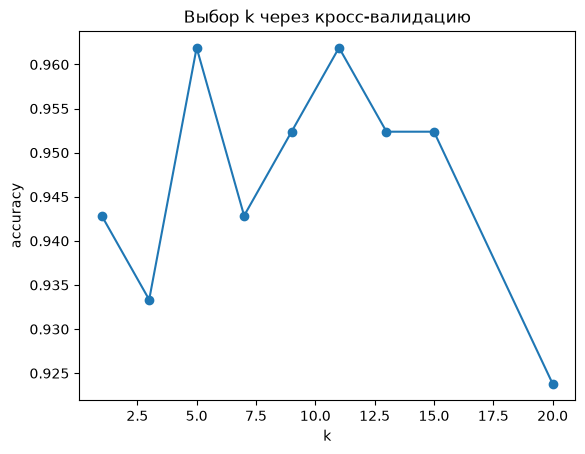

In [165]:
#Выбор k - кросс-валидация
#Поиск оптимального k кросс-валидацией
from sklearn.model_selection import cross_val_score
k_values = (1, 3, 5, 7, 9, 11, 13, 15, 20)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')
    accuracies.append(scores.mean())
    print(f'k={k}, Cross-validated accuracy: {scores.mean():.4f}')

#Визуализация
import matplotlib.pyplot as plt
plt.plot(k_values, accuracies, marker='o')
plt.xlabel('k')
plt.ylabel('accuracy')
plt.title('Выбор k через кросс-валидацию')
plt.show()


In [166]:
#Взвешенный k-NN
#Идея: Учитывать расстояние до соседа. Чем ближе тем больше вес.

def predict_class_weighted(x, X_train, y_train, k):
    #Взвешенное предсказание класса.
    distances = np.sqrt(np.sum((X_train - x) ** 2, axis=1 ))
    k_indices = np.argsort(distances)[:k]
    k_distances = distances[k_indices]
    k_labels = y_train[k_indices]
    #Веса 1/distance^2
    weights = 1 / (k_distances ** 2 + 1e-10)  # Добавляем маленькое число, чтобы избежать деления на ноль

    #Взвешенное голосование
    class_votes = {}
    for label, weight in zip(k_labels, weights):
        for label, weight in zip(k_labels, weights):
            class_weights[label] = class_weights.get(label, 0) + weight
        return max(class_weights, key=class_weights.get)